# Spectral coefficient and apparent-oxygenation fields


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：mouse_oxygen_challenge_spectral_maps

**观测 y：** images(1, 76, 10, 1, 111, 111)；wavelength(1, 10)；spectra(1, 2, 10)；acquisition_time(1, 76, 10)；roi_labels(1, 1, 111, 111)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 76周期Hb/HbO2系数和表观饱和度场。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 声学重建后的波长图由两个消光谱线性混合。本地路径为 `solvers.reconstruct→unmix`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 5, 9, 10, 11, 12, 13, 15（cell编号按文件内从0计）。章节包括：# Spectral coefficient and apparent-oxygenation fields；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；### Oxygen-enhancement comparison retained from the author demonstration；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 不包含原始声学成像；表观饱和度无独立生理GT，ROI为固定支持。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem
This real mouse acquisition measures oxygen-challenge dynamics through 76 cycles of ten optical wavelengths. We reconstruct spatial deoxyhaemoglobin(Hb) and oxyhaemoglobin(HbO2) spectral coefficients and their apparent saturation ratio. These are physiological imaging biomarkers conditional on a shared-fluence spectral model. They are not independently known blood oxygenation or absolute molar haemoglobin.

The selected original method is PATATO's linear spectral unmixing and SO2 calculation, as described in Else et al., JOSS2024, DOI10.21105/joss.05686. We extract the pseudoinverse, explicit spectral forward model and original output/ratio conventions locally. Acoustic initial-pressure reconstruction is a prior author processing stage, not the unknown being solved here.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.physics_model import forward,oxygenation,spectral_relative_residual
from src.solvers import reconstruct,unmix
from src import visualization as vis
images,spectra,labels,wavelength,times=load_data();support=labels>0
reference=np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False)
original=reference['reconstruction'][0];original_so2=reference['saturation'][0]
minutes=(times.mean(axis=1)-times[0,0])/60
names={1:'Reference region',2:'Left tumour',3:'Right tumour'}
print('All observations:',images.shape,'fixed support:',int(support.sum()),'pixels')
print('Recorded extent:',float(times[-1,-1]),'seconds; native10wavelength order:',wavelength)

All observations: (76, 10, 1, 111, 111) fixed support: 1955 pixels
Recorded extent: 998.7371292114258 seconds; native10wavelength order: [700. 730. 750. 760. 770. 800. 820. 840. 850. 880.]


## 2. Data
The author CC-BY4 dataset, DOI10.17863/CAM.93181, contains the full mouse oxygen-enhanced acquisition. All 76 cycles and ten wavelengths are retained. The native333×333 author reference-backprojection images are processed by the unchanged standard3×3uniform convolution and stride3rescaling, giving full nominal field111×111. This is author-standard spatial averaging, not an added crop. The source keeps the nominal24.975mmfield convention after striding; its small endpoint relabeling approximation is documented.

The convolution produces float64 values. Float32 storage was checked before local implementation: relative image L2error2.53×10⁻⁸, and supported saturation changes at most1.19×10⁻⁷ relative to the original full native pipeline. The original method was then run on exactly the stored float32 observations, giving independent fixtures. The native pipeline also bitwise reproduces the author's separately cached HDF5 coefficient images.

Three author-drawn anatomical regions define 1955 supported pixels:33reference,378left tumour and1544right tumour. They are rasterized before inversion. No inferred saturation, residual or coefficient is used to remove a pixel. Outside this fixed geometry the spectral model may yield unstable background ratios; no physiological meaning is assigned to those excluded locations. The measured wavelength images remain complete in the public input.

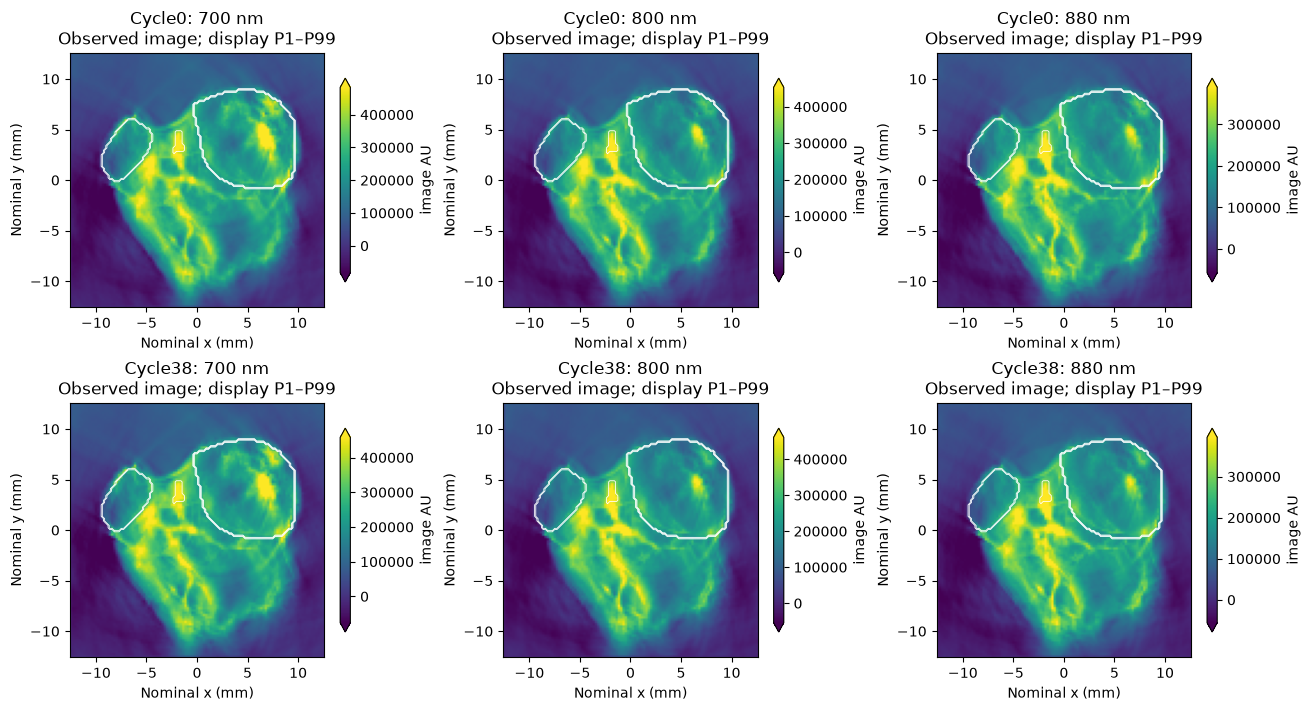

In [2]:
fig,axes=plt.subplots(2,3,figsize=(13,7),layout='constrained')
for row,t in enumerate([0,38]):
    for col,k in enumerate([0,5,9]):
        a=images[t,k,0];lim=tuple(np.quantile(a,[.01,.99]))
        vis.panel(axes[row,col],a,f'Cycle{t}: {wavelength[k]:.0f} nm\nObserved image; display P1–P99','image AU',limits=lim)
        axes[row,col].contour(np.linspace(-12.4875,12.4875,111),np.linspace(-12.4875,12.4875,111),labels[0],levels=[.5,1.5,2.5],colors='white',linewidths=.6)
vis.save(fig,'01_observed_multispectral_images_and_fixed_regions');plt.show()

## 3. Physics
For observed image $I$, cycle $t$, position $r$ and optical wavelength $\lambda$,

$$I(t,r,\lambda)\simeq a_1(t,r)\epsilon_1(\lambda)+a_2(t,r)\epsilon_2(\lambda),\qquad s(t,r)=\frac{a_2(t,r)}{a_1(t,r)+a_2(t,r)}.$$

$\epsilon_1,\epsilon_2$ are independently tabulated Hb/HbO2 decadic extinction spectra in cm⁻¹/M. The coefficients $a$ have image units/(cm⁻¹/M), absorbing unknown fluence, acoustic gain and the natural-versus-decadic absorption factor. A common wavelength-independent intensity scale cancels in $s$; spectral colouring does not. Therefore $s$ is an apparent oxygenation estimate and $a$ is not absolute concentration. Sequential wavelengths also assume negligible within-cycle motion and sufficiently stable physiology.

No additional pulse-energy, water-loss or tissue-fluence correction is applied to the author-supplied reconstructed images. Their acquisition history and arbitrary scale remain explicit, rather than claiming unverified absolute calibration.

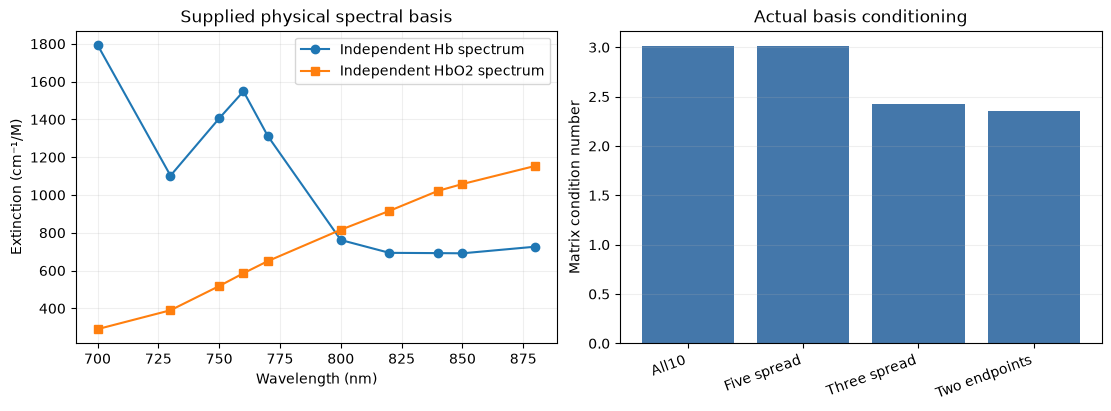

{
  "All10": 3.017418608685159,
  "Five spread": 3.012513313094624,
  "Three spread": 2.4301181887778824,
  "Two endpoints": 2.350441502961598
}


In [3]:
subset_indices={'All10':np.arange(10),'Five spread':[0,2,4,6,9],'Three spread':[0,5,9],'Two endpoints':[0,9]}
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].plot(wavelength,spectra[0],'o-',label='Independent Hb spectrum');axes[0].plot(wavelength,spectra[1],'s-',label='Independent HbO2 spectrum');axes[0].set(xlabel='Wavelength (nm)',ylabel='Extinction (cm⁻¹/M)',title='Supplied physical spectral basis');axes[0].legend();axes[0].grid(alpha=.2)
conditions={k:float(np.linalg.cond(spectra[:,v])) for k,v in subset_indices.items()}
axes[1].bar(range(4),list(conditions.values()),color='#4477aa');axes[1].set_xticks(range(4),list(conditions),rotation=20,ha='right');axes[1].set(title='Actual basis conditioning',ylabel='Matrix condition number');axes[1].grid(axis='y',alpha=.2)
vis.save(fig,'02_independent_spectra_and_conditioning');plt.show();print(json.dumps(conditions,indent=2))

## 4. Method
At each pixel/cycle, let the row vector $i$ contain ten measured values and let $E$ be the2×10spectral matrix. The conditional target minimizes the unweighted wavelength residual

$$J(a)=\sum_w\left(i_w-\sum_c a_cE_{cw}\right)^2,\qquad a=iE^+,$$

where $E^+$ is the Moore–Penrose pseudoinverse with the original NumPy default singular-value cutoff. There is no spatial or temporal regularizer, positivity projection, iterative update, wavelength renormalization or fitted scale. The source casts the coefficients to float32 before computing the float32ratio. The original `nan_invalid=False` convention retains negative or out-of-range estimates; a zero total coefficient is undefined and becomes NaN rather than a chosen physiological value. All supported values are finite and physical in this selected standard run, without post-fit masking.

In [4]:
begin=time.perf_counter();coefficient,saturation=reconstruct(images,spectra,labels);runtime=time.perf_counter()-begin
Path('output').mkdir(exist_ok=True);np.savez_compressed('output/reconstruction.npz',reconstruction=coefficient[None],saturation=saturation[None])
agreement={name:vis.metrics(a[...,support],b[...,support]) for name,a,b in [('Hb',coefficient[:,0],original[:,0]),('HbO2',coefficient[:,1],original[:,1]),('saturation',saturation,original_so2)]}
relative=spectral_relative_residual(coefficient,images,spectra,support)
print(json.dumps(dict(fresh_seconds=runtime,agreement_with_independent_original=agreement,spectral_relative_residual=relative),indent=2))
print('Negative supported coefficients:',int(np.count_nonzero(coefficient[...,support]<0)))
print('Out-of-range supported apparent saturation:',int(np.count_nonzero((saturation[...,support]<0)|(saturation[...,support]>1))))

{
  "fresh_seconds": 0.03452410000318196,
  "agreement_with_independent_original": {
    "Hb": {
      "ncc": 1.0000000000000002,
      "nrmse": 0.0
    },
    "HbO2": {
      "ncc": 0.9999999999999999,
      "nrmse": 0.0
    },
    "saturation": {
      "ncc": 1.0,
      "nrmse": 0.0
    }
  },
  "spectral_relative_residual": 0.10271870169357335
}
Negative supported coefficients: 0
Out-of-range supported apparent saturation: 0


## 5. Results
The reference in the next comparison is this task's independent reproduced author result on the exact stored observations. It is not truth. Every fresh map below is computed by local cleaned code. Fixed anatomical support is applied only to the outputs, while all ten full-field wavelength observations were available to the fit. The dynamic plots retain every cycle and do not invent unrecorded gas-valve switch times.

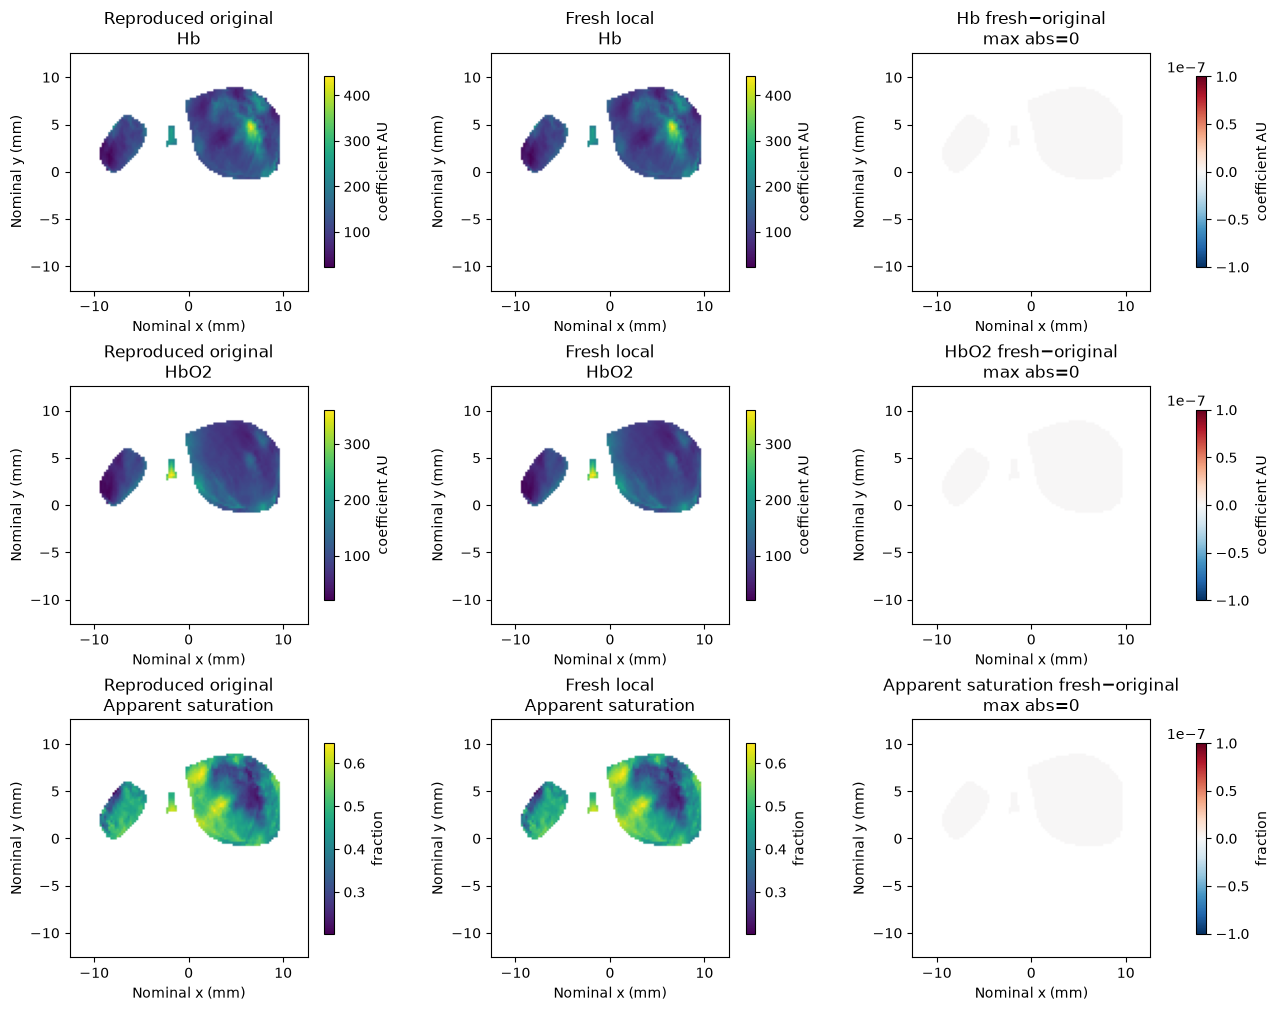

In [5]:
fig,axes=plt.subplots(3,3,figsize=(13,10),layout='constrained');t=38
for row,(fresh,old,name,unit) in enumerate([(coefficient[t,0,0],original[t,0,0],'Hb','coefficient AU'),(coefficient[t,1,0],original[t,1,0],'HbO2','coefficient AU'),(saturation[t,0],original_so2[t,0],'Apparent saturation','fraction')]):
    lim=(float(old[support[0]].min()),float(old[support[0]].max()))
    for col,(a,title) in enumerate([(old,'Reproduced original'),(fresh,'Fresh local')]):vis.panel(axes[row,col],np.where(support[0],a,np.nan),title+'\n'+name,unit,limits=lim)
    difference=fresh-old;limit=max(float(abs(difference).max()),1e-7)
    vis.panel(axes[row,2],np.where(support[0],difference,np.nan),name+' fresh−original\nmax abs='+f'{abs(difference).max():.2g}',unit,'RdBu_r',(-limit,limit))
vis.save(fig,'03_original_and_fresh_all_physical_fields');plt.show()

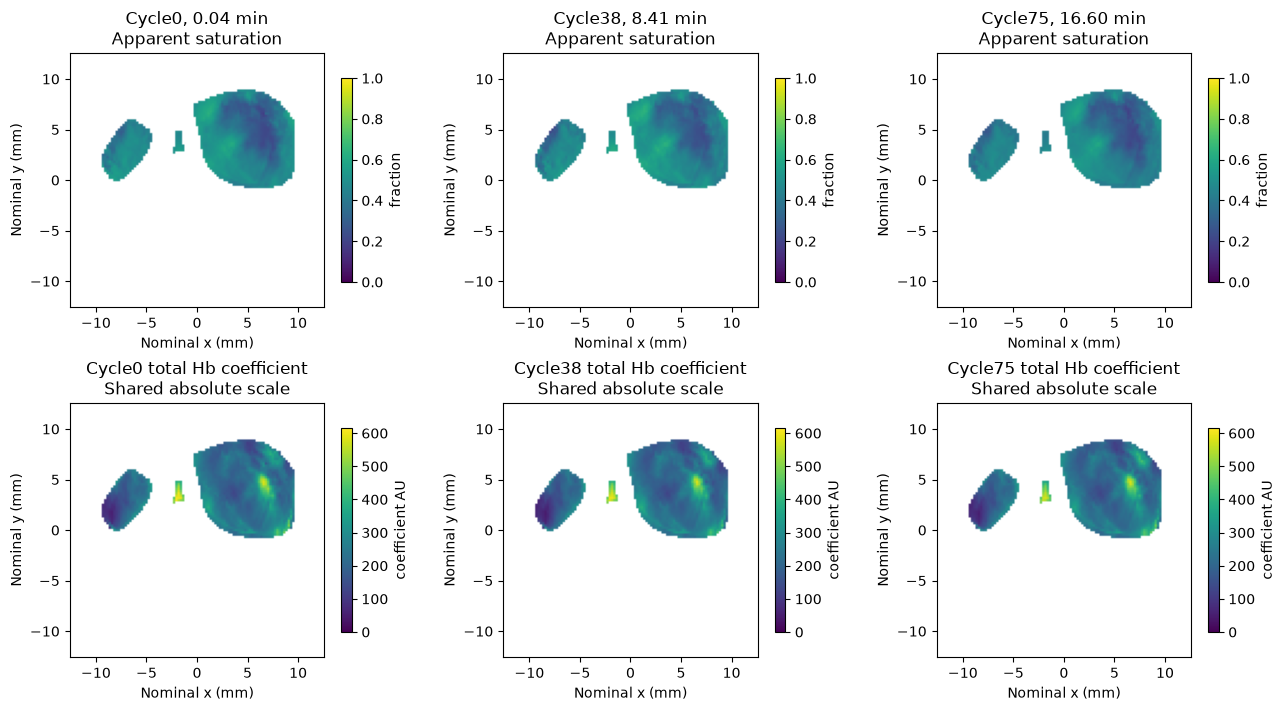

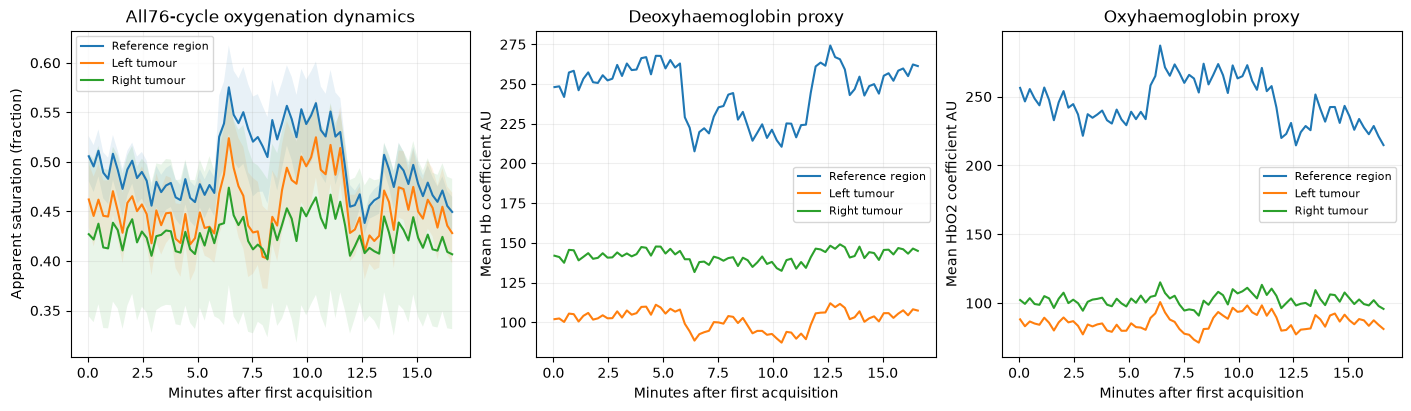

Bands are pixel interquartile ranges, not uncertainty across independent animals.


In [6]:
fig,axes=plt.subplots(2,3,figsize=(13,7),layout='constrained')
for col,t in enumerate([0,38,75]):
    vis.panel(axes[0,col],np.where(support[0],saturation[t,0],np.nan),f'Cycle{t}, {minutes[t]:.2f} min\nApparent saturation','fraction',limits=(0,1))
    thb=coefficient[t,0,0]+coefficient[t,1,0]
    vis.panel(axes[1,col],np.where(support[0],thb,np.nan),f'Cycle{t} total Hb coefficient\nShared absolute scale','coefficient AU',limits=(0,float((coefficient[:,0]+coefficient[:,1])[...,support].max())))
vis.save(fig,'04_full_sequence_spatial_snapshots');plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained');region_traces={}
for index,name in names.items():
    region=labels==index
    # Boolean indexing uses a stable time-first reshape explicitly.
    s=saturation[:,region];hb=coefficient[:,0][:,region];hbo=coefficient[:,1][:,region]
    region_traces[name]=dict(saturation=s.mean(1),Hb=hb.mean(1),HbO2=hbo.mean(1))
    axes[0].plot(minutes,s.mean(1),label=name);q=np.quantile(s,[.25,.75],axis=1);axes[0].fill_between(minutes,q[0],q[1],alpha=.1)
    axes[1].plot(minutes,hb.mean(1),label=name);axes[2].plot(minutes,hbo.mean(1),label=name)
for ax,title,ylabel in zip(axes,['All76-cycle oxygenation dynamics','Deoxyhaemoglobin proxy','Oxyhaemoglobin proxy'],['Apparent saturation (fraction)','Mean Hb coefficient AU','Mean HbO2 coefficient AU']):ax.set(title=title,xlabel='Minutes after first acquisition',ylabel=ylabel);ax.legend(fontsize=8);ax.grid(alpha=.2)
vis.save(fig,'05_actual_regional_dynamics');plt.show()
print('Bands are pixel interquartile ranges, not uncertainty across independent animals.')

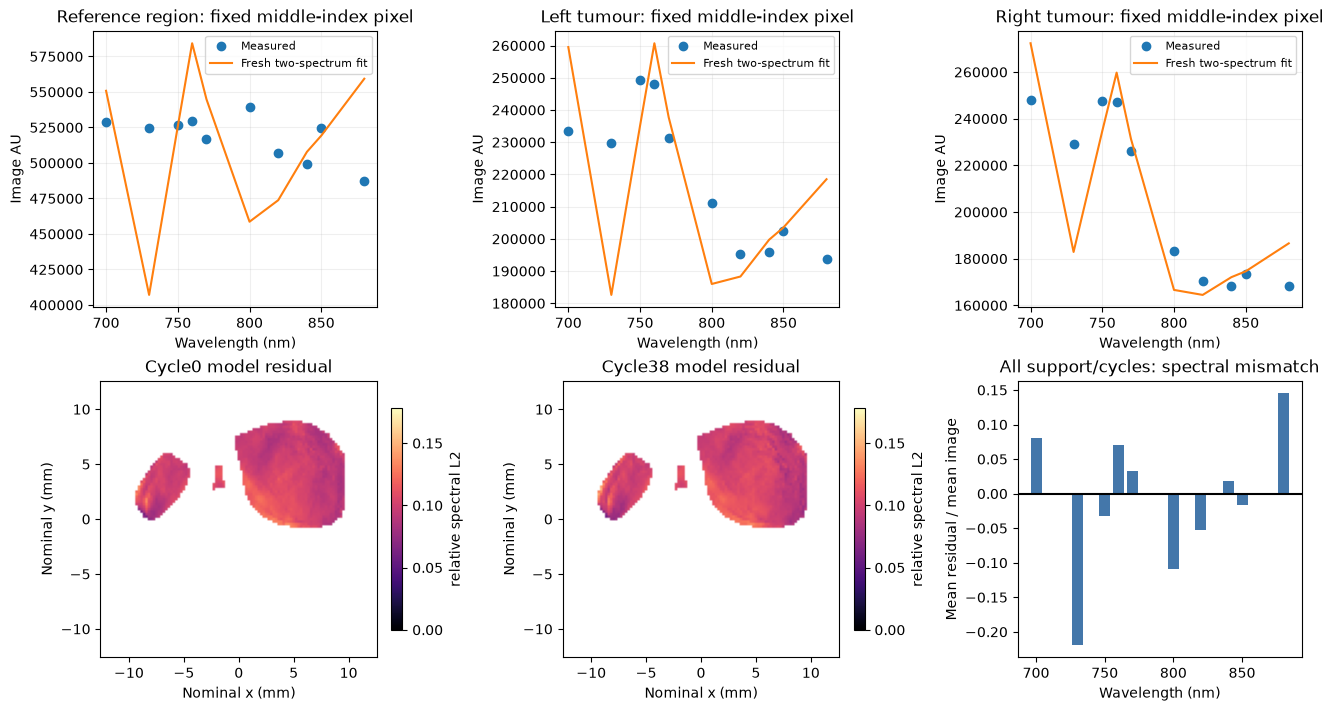

Representative pixels chosen by fixed ROI geometry; no fit-quality selection.


In [7]:
prediction=forward(coefficient,spectra);residual=prediction-images
fig,axes=plt.subplots(2,3,figsize=(13,7),layout='constrained');example_coordinates=[]
for col,(index,name) in enumerate(names.items()):
    positions=np.argwhere(labels[0]==index);y,x=positions[len(positions)//2];example_coordinates.append([int(y),int(x)])
    axes[0,col].plot(wavelength,images[38,:,0,y,x],'o',label='Measured');axes[0,col].plot(wavelength,prediction[38,:,0,y,x],'-',label='Fresh two-spectrum fit');axes[0,col].set(title=f'{name}: fixed middle-index pixel',xlabel='Wavelength (nm)',ylabel='Image AU');axes[0,col].legend(fontsize=8);axes[0,col].grid(alpha=.2)
local_residual=np.linalg.norm(residual,axis=1)/np.linalg.norm(images,axis=1)
for col,t in enumerate([0,38]):vis.panel(axes[1,col],np.where(support[0],local_residual[t,0],np.nan),f'Cycle{t} model residual','relative spectral L2','magma',limits=(0,float(local_residual[...,support].max())))
# Use aggregate residual per wavelength without unstable division by background pixels.
ratio=residual[...,support].mean(axis=(0,2))/images[...,support].mean(axis=(0,2))
axes[1,2].bar(wavelength,ratio,width=8,color='#4477aa');axes[1,2].axhline(0,color='black');axes[1,2].set(title='All support/cycles: spectral mismatch',xlabel='Wavelength (nm)',ylabel='Mean residual / mean image')
vis.save(fig,'06_actual_spectral_fits_and_residuals');plt.show();print('Representative pixels chosen by fixed ROI geometry; no fit-quality selection.')

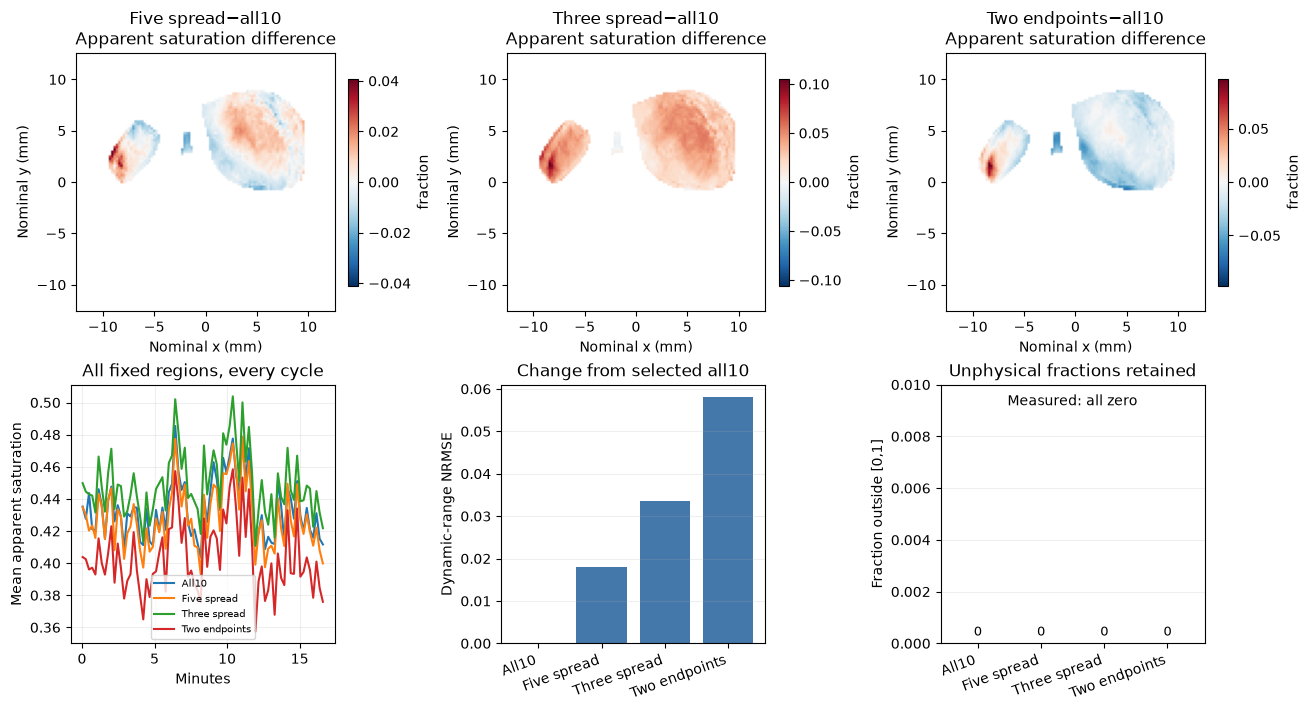

[
  {
    "method": "All10",
    "condition": 3.017418608685159,
    "seconds": 0.04389919999812264,
    "saturation_nrmse_vs_default": 0.0,
    "negative_coefficient_fraction": 0.0,
    "outside_0_1_fraction": 0.0
  },
  {
    "method": "Five spread",
    "condition": 3.012513313094624,
    "seconds": 0.03565289999824017,
    "saturation_nrmse_vs_default": 0.017903068752003082,
    "negative_coefficient_fraction": 0.0,
    "outside_0_1_fraction": 0.0
  },
  {
    "method": "Three spread",
    "condition": 2.4301181887778824,
    "seconds": 0.024336400005267933,
    "saturation_nrmse_vs_default": 0.033521408349329374,
    "negative_coefficient_fraction": 0.0,
    "outside_0_1_fraction": 0.0
  },
  {
    "method": "Two endpoints",
    "condition": 2.350441502961598,
    "seconds": 0.02227679999487009,
    "saturation_nrmse_vs_default": 0.05810424872477648,
    "negative_coefficient_fraction": 0.0,
    "outside_0_1_fraction": 0.0
  }
]


In [8]:
subset_maps={};subset_rows=[]
for name,indices in subset_indices.items():
    begin=time.perf_counter();a,s=reconstruct(images,spectra,labels,wavelength_indices=indices);seconds=time.perf_counter()-begin;subset_maps[name]=s
    subset_rows.append(dict(method=name,condition=conditions[name],seconds=seconds,saturation_nrmse_vs_default=vis.metrics(s[...,support],saturation[...,support])['nrmse'],negative_coefficient_fraction=float(np.mean(a[...,support]<0)),outside_0_1_fraction=float(np.mean((s[...,support]<0)|(s[...,support]>1)))))
fig,axes=plt.subplots(2,3,figsize=(13,7),layout='constrained')
for col,(name,s) in enumerate(list(subset_maps.items())[1:]):
    d=s[38,0]-saturation[38,0];lim=max(float(abs(d[support[0]]).max()),1e-7)
    vis.panel(axes[0,col],np.where(support[0],d,np.nan),name+'−all10\nApparent saturation difference','fraction','RdBu_r',(-lim,lim))
for name,s in subset_maps.items():axes[1,0].plot(minutes,s[:,support].mean(1),label=name)
axes[1,0].set(title='All fixed regions, every cycle',xlabel='Minutes',ylabel='Mean apparent saturation');axes[1,0].legend(fontsize=7);axes[1,0].grid(alpha=.2)
for ax,key,title in [(axes[1,1],'saturation_nrmse_vs_default','Change from selected all10'),(axes[1,2],'outside_0_1_fraction','Unphysical fractions retained')]:
    ax.bar(range(4),[r[key] for r in subset_rows],color='#4477aa');ax.set_xticks(range(4),[r['method'] for r in subset_rows],rotation=20,ha='right');ax.set(title=title,ylabel='Dynamic-range NRMSE' if 'nrmse' in key else 'Fraction outside [0,1]');ax.grid(axis='y',alpha=.2)
    if key=='outside_0_1_fraction':
        ax.set_ylim(0,.01)
        for k,row in enumerate(subset_rows):ax.text(k,.0003,f"{row[key]:.0f}",ha='center',fontsize=9)
        ax.text(.5,.92,'Measured: all zero',transform=ax.transAxes,ha='center',fontsize=10)
vis.save(fig,'07_actual_wavelength_subset_sensitivity');plt.show();print(json.dumps(subset_rows,indent=2))

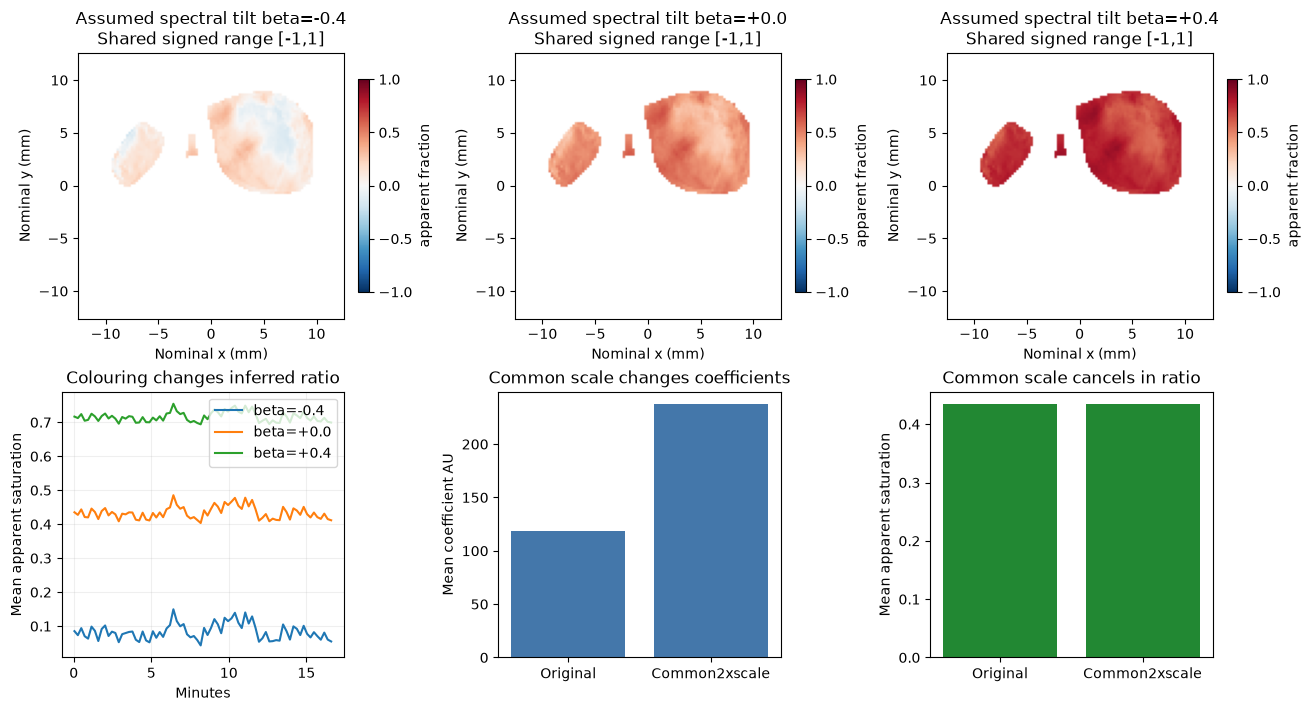

{
  "spectral_tilt": [
    {
      "beta": -0.4,
      "mean_saturation": 0.08378655463457108,
      "nrmse_vs_default": 0.5586137099446546,
      "outside_0_1_fraction": 0.2531565486606542
    },
    {
      "beta": 0,
      "mean_saturation": 0.43405434489250183,
      "nrmse_vs_default": 0.0,
      "outside_0_1_fraction": 0.0
    },
    {
      "beta": 0.4,
      "mean_saturation": 0.7160309553146362,
      "nrmse_vs_default": 0.4500633777121366,
      "outside_0_1_fraction": 0.0
    }
  ],
  "common_scale_check": {
    "coefficient_factor2_max_abs_difference": 0.0,
    "saturation_max_abs_difference": 0.0
  }
}
Tilt branches are deliberate model-violation sensitivities. No actual fluence correction or known true oxygenation is inferred.


In [9]:
tilt_maps={};tilt_rows=[]
for beta in [-.4,0,.4]:
    modified=(images*np.exp(beta*(wavelength-800)/100)[None,:,None,None,None]).astype(np.float32)
    a,s=reconstruct(modified,spectra,labels);tilt_maps[beta]=s
    tilt_rows.append(dict(beta=beta,mean_saturation=float(s[...,support].mean()),nrmse_vs_default=vis.metrics(s[...,support],saturation[...,support])['nrmse'],outside_0_1_fraction=float(np.mean((s[...,support]<0)|(s[...,support]>1)))))
scaled,scaled_s=reconstruct(images*2,spectra,labels)
scale_check=dict(coefficient_factor2_max_abs_difference=float(np.max(abs(scaled-coefficient*2))),saturation_max_abs_difference=float(np.max(abs(scaled_s-saturation))))
fig,axes=plt.subplots(2,3,figsize=(13,7),layout='constrained')
for col,(beta,s) in enumerate(tilt_maps.items()):
    vis.panel(axes[0,col],np.where(support[0],s[38,0],np.nan),f'Assumed spectral tilt beta={beta:+.1f}\nShared signed range [-1,1]','apparent fraction','RdBu_r',limits=(-1,1))
    axes[1,0].plot(minutes,s[:,support].mean(1),label=f'beta={beta:+.1f}')
axes[1,0].set(title='Colouring changes inferred ratio',xlabel='Minutes',ylabel='Mean apparent saturation');axes[1,0].legend();axes[1,0].grid(alpha=.2)
axes[1,1].bar(['Original','Common2xscale'],[float(np.mean(coefficient[...,support])),float(np.mean(scaled[...,support]))],color='#4477aa');axes[1,1].set(title='Common scale changes coefficients',ylabel='Mean coefficient AU')
axes[1,2].bar(['Original','Common2xscale'],[float(np.mean(saturation[...,support])),float(np.mean(scaled_s[...,support]))],color='#228833');axes[1,2].set(title='Common scale cancels in ratio',ylabel='Mean apparent saturation')
vis.save(fig,'08_shared_scale_and_spectral_colouring');plt.show();print(json.dumps(dict(spectral_tilt=tilt_rows,common_scale_check=scale_check),indent=2))
print('Tilt branches are deliberate model-violation sensitivities. No actual fluence correction or known true oxygenation is inferred.')

### Oxygen-enhancement comparison retained from the author demonstration
The paper's oxygen-challenge analysis also summarizes a baseline-to-challenge change. We preserve that scientific comparison using the unchanged original reference-curve heuristic, independently captured before extracting this additional helper. Its inferred change points are signal-derived estimates, not hardware gas-valve records. It smooths the reference-region traces with the original median/Gaussian conventions, detects derivative extrema, and leaves five cycles around transitions out of the interval averages. The separate ICG-injection dataset is outside this bound oxygen-challenge acquisition and is not represented as a missing or zero-valued method.

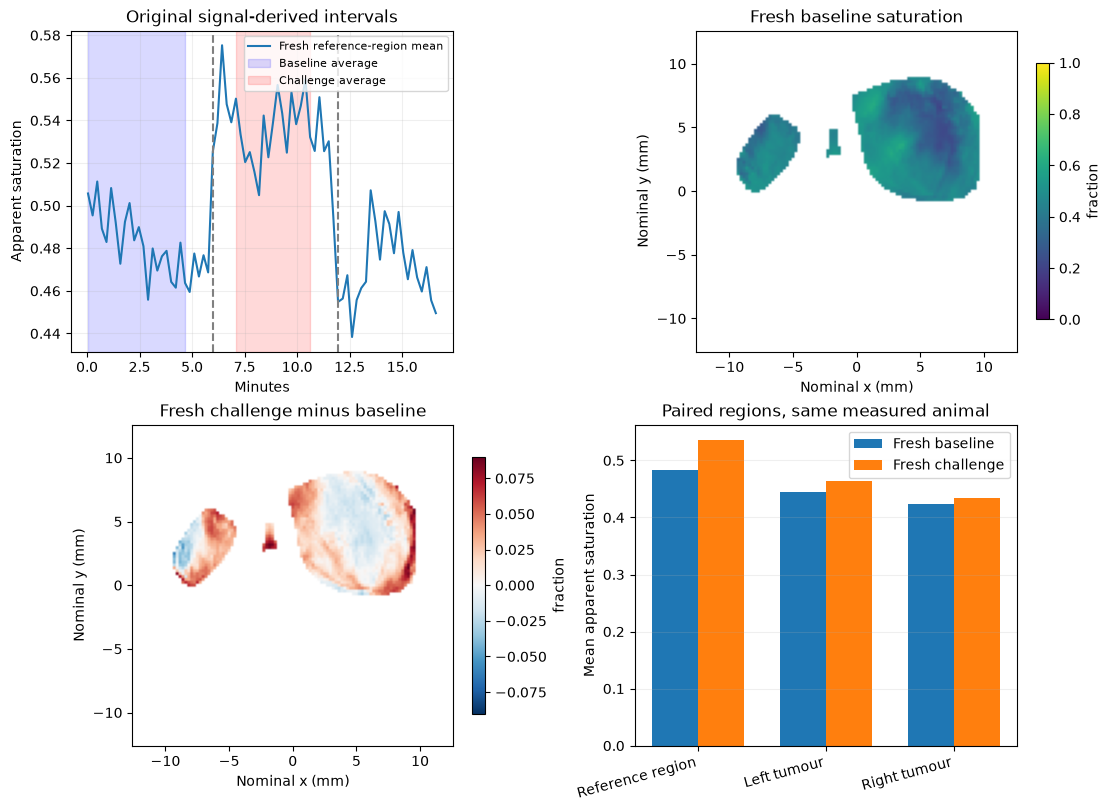

Inferred original/fresh cycle boundaries: [0, 27, 54, 75] five-cycle transition buffer
Enhancement max difference from independently reproduced original: 0.0


In [10]:
from src.physics_model import enhancement_summary
steps,baseline,baseline_std,enhancement=enhancement_summary(saturation,labels==1)
upstream_enhancement=np.load('test/fixtures/upstream_enhancement.npz',allow_pickle=False)
assert np.array_equal(steps,upstream_enhancement['steps'])
for a,key in [(baseline,'baseline'),(baseline_std,'baseline_std'),(enhancement,'delta')]:assert np.array_equal(a[support],upstream_enhancement[key][support])
fig,axes=plt.subplots(2,2,figsize=(11,8),layout='constrained')
trace=saturation[:,labels==1].mean(1);axes[0,0].plot(minutes,trace,label='Fresh reference-region mean')
for step in steps[1:-1]:axes[0,0].axvline(minutes[step],color='gray',ls='--')
axes[0,0].axvspan(minutes[steps[0]],minutes[steps[1]-6],alpha=.15,color='blue',label='Baseline average')
axes[0,0].axvspan(minutes[steps[1]+5],minutes[steps[2]-6],alpha=.15,color='red',label='Challenge average')
axes[0,0].set(title='Original signal-derived intervals',xlabel='Minutes',ylabel='Apparent saturation');axes[0,0].legend(fontsize=8);axes[0,0].grid(alpha=.2)
vis.panel(axes[0,1],np.where(support[0],baseline[0],np.nan),'Fresh baseline saturation','fraction',limits=(0,1))
limit=float(abs(enhancement[support]).max());vis.panel(axes[1,0],np.where(support[0],enhancement[0],np.nan),'Fresh challenge minus baseline','fraction','RdBu_r',(-limit,limit))
x=np.arange(3);before=[float(baseline[labels==k].mean()) for k in names];after=[float((baseline+enhancement)[labels==k].mean()) for k in names]
axes[1,1].bar(x-.18,before,width=.36,label='Fresh baseline');axes[1,1].bar(x+.18,after,width=.36,label='Fresh challenge');axes[1,1].set_xticks(x,list(names.values()),rotation=15,ha='right');axes[1,1].set(title='Paired regions, same measured animal',ylabel='Mean apparent saturation');axes[1,1].legend();axes[1,1].grid(axis='y',alpha=.2)
vis.save(fig,'09_original_oxygen_enhancement_comparison');plt.show()
print('Inferred original/fresh cycle boundaries:',steps,'five-cycle transition buffer')
print('Enhancement max difference from independently reproduced original:',float(np.max(abs(enhancement[support]-upstream_enhancement['delta'][support]))))

In [11]:
import importlib.util
spec=importlib.util.spec_from_file_location('independent_spectral_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(root/'output/reconstruction.npz');assert report['passed'],report
Path('output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8');print(json.dumps(report,indent=2))
assert vis.metrics(np.array([1.,3.]),np.array([2.,4.]))==judge.metrics(np.array([1.,3.]),np.array([2.,4.]))
if os.environ.get('IMAGING_FIGURE_DIR'):
    private=Path(os.environ['IMAGING_FIGURE_DIR'])
    np.savez_compressed(private/'numerical_sources.npz',images=images,spectra=spectra,wavelength=wavelength,times=times,labels=labels,original_coefficients=original,original_saturation=original_so2,fresh_coefficients=coefficient,fresh_saturation=saturation,spectral_prediction=prediction,spectral_residual=residual,local_relative_residual=local_residual,example_coordinates=np.array(example_coordinates),enhancement_steps=np.array(steps),baseline_saturation=baseline,baseline_std=baseline_std,enhancement=enhancement,original_enhancement=upstream_enhancement['delta'],**{f'subset_{k}':v for k,v in enumerate(subset_maps.values())},**{f'tilt_{k}':v for k,v in enumerate(tilt_maps.values())})
    (private/'scientific_measurements.json').write_text(json.dumps(dict(fresh_seconds=runtime,agreement=agreement,spectral_relative_residual=relative,subset_sensitivity=subset_rows,tilt_sensitivity=tilt_rows,common_scale_check=scale_check,enhancement_inferred_steps=[int(x) for x in steps],enhancement_max_original_difference=float(np.max(abs(enhancement[support]-upstream_enhancement['delta'][support]))),judge=report),indent=2,allow_nan=False),encoding='utf-8')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "Hb_ncc": 1.0000000000000002,
    "Hb_nrmse": 0.0,
    "HbO2_ncc": 0.9999999999999999,
    "HbO2_nrmse": 0.0,
    "saturation_ncc": 1.0,
    "saturation_nrmse": 0.0,
    "spectral_relative_residual": 0.10271870169357335
  },
  "thresholds": {
    "Hb_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "Hb_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "HbO2_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "HbO2_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "saturation_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "saturation_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "spectral_relative_residual": {
      "comparison": "<=",
      "boundary": 0.10374589315541642
    }
  },
  "errors": []
}


## 6. Conclusion
The fresh explicit local pseudoinverse and ratio reproduce the original on all76cycles and1955fixed anatomical pixels. The spatial and temporal views reveal measured differences among regions without replacing maps by a few scalar fits. The selected estimate retains positive coefficients and finite fractions on all fixed support, with a roughly10.3%spectral residual that remains visible.

Known-spectrum conditioning, wavelength subsets and deliberate spectral-colouring perturbations show the limits of interpretation. A common amplitude scale cancels in the ratio; an unknown wavelength-dependent scale can change it. These apparent oxygenation maps therefore demonstrate reproducible conditional spectral inversion, not an independently calibrated absolute haemoglobin measurement or known true physiological oxygenation. No gas-switch times, missing method or hidden target calibration is invented. Full provenance, storage-precision checks, independent physics and strict NPZ/Judge evidence are in `test/validation.md`.